# PCPP

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Simulations

In [2]:
def sample_pcpp_exact(n, theta, omega, random_state=None):
    """
    Generate a sample from the exact PCPP generative process.
    Parameters
    ----------
    n : int
        Number of observations.
    theta : float
        Poisson parameter for the number of potential communities.
    omega : float
        Competition parameter in [0, 1].
    random_state : int or None
        Random seed.
    Returns
    -------
    dict
        Generated number of communities, tournament outcomes, allocation
        weights, assignments, and induced partition.
    """
    if n < 1:
        raise ValueError("n must be positive.")
    if theta <= 0:
        raise ValueError("theta must be positive.")
    if not 0 <= omega <= 1:
        raise ValueError("omega must belong to [0, 1].")
    rng = np.random.default_rng(random_state)
    # 1. Number of potential communities
    M = 1 + rng.poisson(theta)
    # 2. Random tournament
    D = np.zeros(M, dtype=int)
    tournament = []
    for j in range(M):
        for l in range(j + 1, M):
            win = rng.binomial(1, 0.5)
            if win == 1:
                D[j] += 1
                winner, loser = j, l
            else:
                D[l] += 1
                winner, loser = l, j
            tournament.append((winner, loser))
    # 3. Allocation weights
    W = (1 - omega) / M + omega * (1 + 2 * D) / M**2
    # Numerical normalization
    W = W / W.sum()
    # 4. Allocation of observations
    xi = rng.choice(M, size=n, p=W)
    # 5. Induced partition
    labels, inverse, counts = np.unique(xi, return_inverse=True, return_counts=True)
    blocks = [np.where(inverse == k)[0].tolist() for k in range(len(labels))]
    return {"process": "Exact PCPP", "M": M, "D": D, "W": W,
        "tournament": tournament, "xi_raw": xi, "canonical_xi": inverse, "K_n": len(labels),
        "block_sizes": counts.tolist(), "blocks": blocks}
def sample_pcpp_approximate(n, theta, omega, random_state=None):
    """
    Generate a sample from the Dirichlet-approximated PCPP.
    Conditional on M, the allocation weights follow a symmetric
    Dirichlet distribution with parameter
        alpha_M = M / omega**2 - 1 / M.
    For omega = 0, the allocation weights are uniform.
    """
    if n < 1:
        raise ValueError("n must be positive.")
    if theta <= 0:
        raise ValueError("theta must be positive.")
    if not 0 <= omega <= 1:
        raise ValueError("omega must belong to [0, 1].")
    rng = np.random.default_rng(random_state)
    # 1. Number of potential communities
    M = 1 + rng.poisson(theta)
    # 2. Approximate allocation weights
    if omega == 0 or M == 1:
        W = np.full(M, 1.0 / M)
        alpha_M = None
    else:
        alpha_M = M / omega**2 - 1 / M
        if alpha_M <= 0:
            raise ValueError("The Dirichlet parameter must be positive.")
        W = rng.dirichlet(np.full(M, alpha_M))
    # 3. Allocation of observations
    xi = rng.choice(M, size=n, p=W)
    # 4. Induced partition
    labels, inverse, counts = np.unique(xi, return_inverse=True, return_counts=True)
    blocks = [np.where(inverse == k)[0].tolist() for k in range(len(labels))]

    return {"process": "Approximate PCPP", "M": M, "alpha_M": alpha_M, "D": None,
        "W": W, "tournament": None, "xi_raw": xi, "canonical_xi": inverse, "K_n": len(labels),
        "block_sizes": counts.tolist(), "blocks": blocks}


In [3]:
def compare_pcpp_processes(n, theta, omega, n_simulations=5000,random_state=123):
    """
    Compare the exact and approximate PCPP through Monte Carlo simulation.
    """
    rng = np.random.default_rng(random_state)
    results = []
    for simulation in range(n_simulations):
        seed_exact = int(rng.integers(0, 2**32 - 1))
        seed_approx = int(rng.integers(0, 2**32 - 1))
        exact_sample = sample_pcpp_exact(n=n, theta=theta, omega=omega, random_state=seed_exact)
        approximate_sample = sample_pcpp_approximate(n=n,theta=theta,omega=omega,random_state=seed_approx)
        for sample in [exact_sample, approximate_sample]:
            largest_block = max(sample["block_sizes"])
            results.append({"simulation": simulation, "process": sample["process"],
            "K_n": sample["K_n"], "largest_block": largest_block, "largest_block_proportion": largest_block / n})
    results_df = pd.DataFrame(results)
    summary = (results_df.groupby("process").agg(mean_K_n=("K_n", "mean"),sd_K_n=("K_n", "std"),
            mean_largest_block=("largest_block", "mean"), mean_largest_block_proportion=("largest_block_proportion", "mean"))
            .reset_index())
    return results_df, summary

In [22]:
n = 50
theta = 5
omega = 0.5
results_df, summary = compare_pcpp_processes(n=n, theta=theta, omega=omega, n_simulations=100000,random_state=123)
display(summary)

,process,mean_K_n,sd_K_n,mean_largest_block,mean_largest_block_proportion
0,Approximate PCPP,5.98565,2.206158,14.51246,0.290249
1,Exact PCPP,5.97028,2.206990,14.55947,0.291189


In [23]:
def study_omega_effect(n,theta,omega_values,n_simulations=5000,random_state=123):
    """
    Study the effect of omega on the exact and approximate PCPP.
    """
    rng = np.random.default_rng(random_state)
    results = []
    for omega in omega_values:
        for simulation in range(n_simulations):
            seed_exact = int(rng.integers(0, 2**32 - 1))
            seed_approx = int(rng.integers(0, 2**32 - 1))
            exact_sample = sample_pcpp_exact(n=n, theta=theta, omega=omega, random_state=seed_exact)
            approximate_sample = sample_pcpp_approximate(n=n,theta=theta,omega=omega,random_state=seed_approx)
            for sample in [exact_sample, approximate_sample]:
                largest_block = max(sample["block_sizes"])
                results.append({"omega": omega, "simulation": simulation, "process": sample["process"],
                    "K_n": sample["K_n"], "largest_block": largest_block, "largest_block_proportion": largest_block / n})
    results_df = pd.DataFrame(results)
    summary = (results_df
        .groupby(["omega", "process"])
        .agg(mean_K_n=("K_n", "mean"), sd_K_n=("K_n", "std"), mean_largest_block=("largest_block", "mean"),
        mean_largest_block_proportion=("largest_block_proportion", "mean"))
        .reset_index())
    return results_df, summary

In [24]:
omega_values = [0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]
results_omega, summary_omega = study_omega_effect(n=n,theta=theta,omega_values=omega_values,n_simulations=100000,random_state=123)
display(summary_omega)

,omega,process,mean_K_n,sd_K_n,mean_largest_block,mean_largest_block_proportion
0,0.0,Approximate PCPP,5.98999,2.210113,13.61183,0.272237
1,0.0,Exact PCPP,5.97519,2.212362,13.64680,0.272936
2,0.1,Approximate PCPP,5.99512,2.228117,13.66525,0.273305
3,0.1,Exact PCPP,5.99402,2.224651,13.65601,0.273120
4,0.2,Approximate PCPP,5.99731,2.217740,13.75826,0.275165
5,0.2,Exact PCPP,5.98693,2.219651,13.79459,0.275892
6,0.3,Approximate PCPP,5.99316,2.219627,13.96793,0.279359
7,0.3,Exact PCPP,5.98773,2.205726,13.95145,0.279029
8,0.4,Approximate PCPP,5.97192,2.206300,14.25394,0.285079
9,0.4,Exact PCPP,5.98722,2.217099,14.23067,0.284613


## Figures

In [25]:
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2,
    "lines.markersize": 7,
    "text.usetex": False})

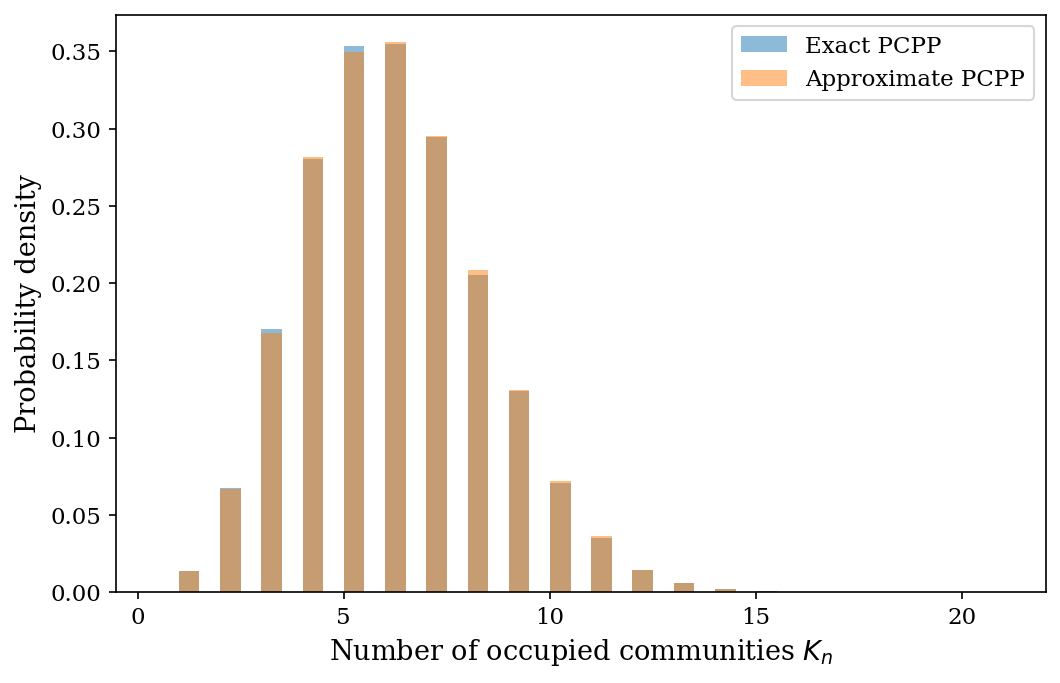

In [26]:
plt.figure(figsize=(8, 5))
for process in results_df["process"].unique():
    subset = results_df[results_df["process"] == process]
    plt.hist(subset["K_n"], bins=np.arange(0.5, 20 + 1.5, 0.5), density=True, alpha=0.5, label=process)
plt.xlabel("Number of occupied communities $K_n$")
plt.ylabel("Probability density")
plt.legend()
plt.savefig("PCPP_simulation_number_occuped_communities.pdf", bbox_inches="tight")
plt.show()

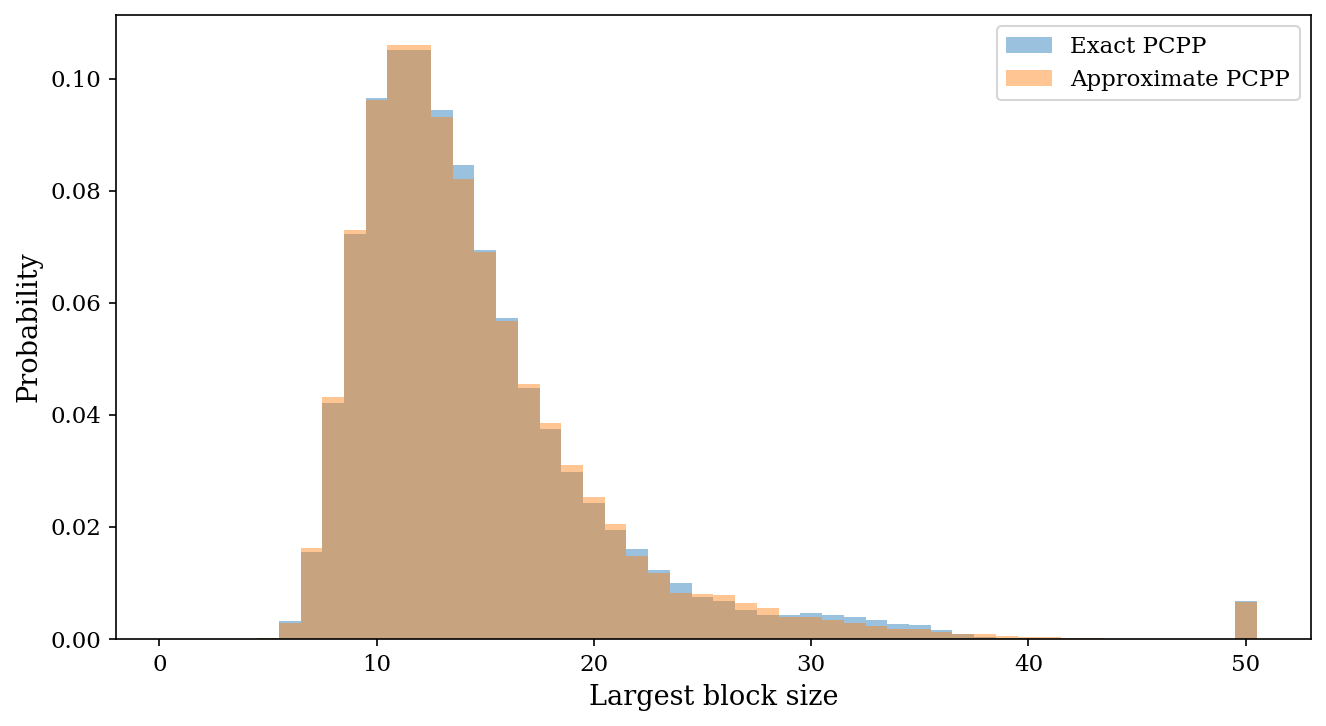

In [27]:
bins = np.arange(0.5, n + 1.5, 1)
plt.figure(figsize=(9, 5))
for process in results_df["process"].unique():
    subset = results_df[results_df["process"] == process]
    plt.hist(subset["largest_block"],bins=bins,density=True,alpha=0.45,label=process)
plt.xlabel("Largest block size")
plt.ylabel("Probability")
plt.legend()
plt.tight_layout()
plt.savefig("PCPP_simulation_largest_block.pdf", bbox_inches="tight")
plt.show()

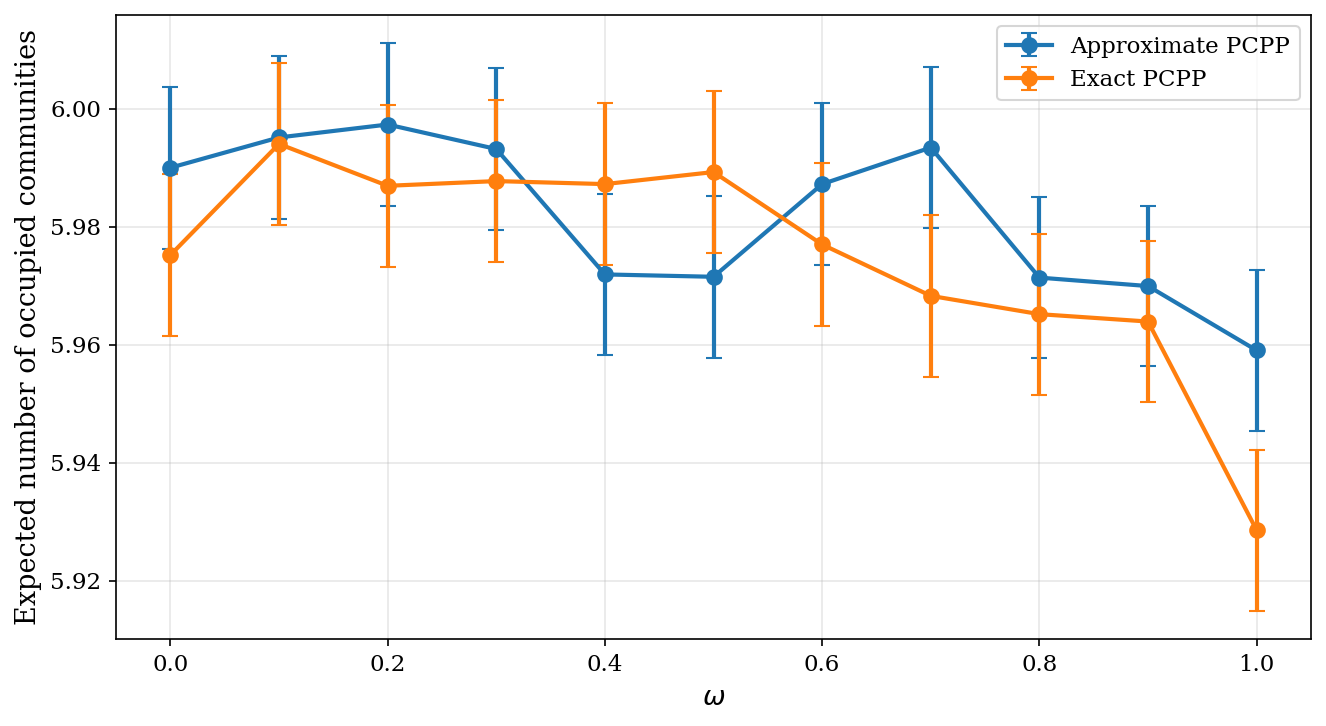

In [33]:
plt.figure(figsize=(9, 5))
for process in summary_omega["process"].unique():
    subset = summary_omega[summary_omega["process"] == process].sort_values("omega")
    se = subset["sd_K_n"] / np.sqrt(100000)
    ci = 1.96 * se
    plt.errorbar(subset["omega"],subset["mean_K_n"],yerr=ci,marker="o",capsize=4,linewidth=2,label=process)
plt.xlabel(r"$\omega$")
plt.ylabel(r"Expected number of occupied communities")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("PCPP_simulation_expected_communities_vs_omega.pdf", bbox_inches="tight")
plt.show()

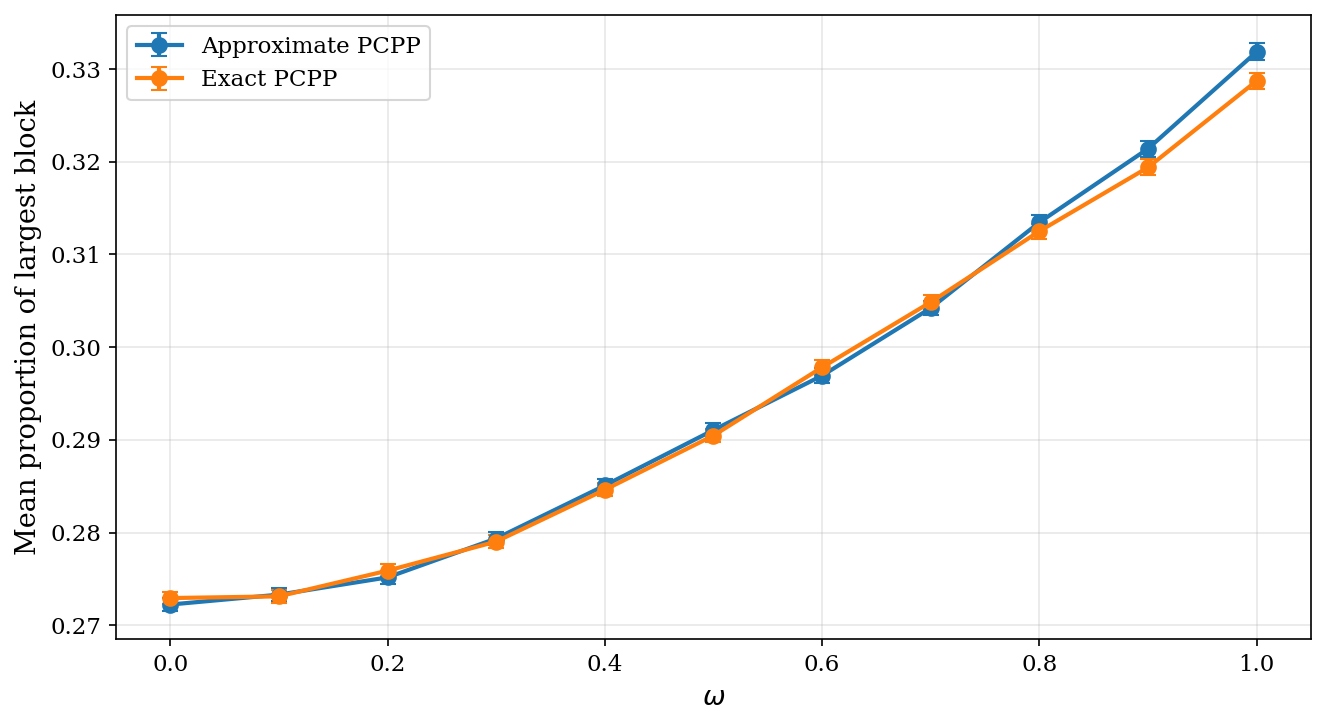

In [34]:
summary_largest = (results_omega.groupby(["omega", "process"])
    .agg(mean=("largest_block_proportion", "mean"),sd=("largest_block_proportion", "std"),
        count=("largest_block_proportion", "count")).reset_index())
summary_largest["se"] = (summary_largest["sd"] /np.sqrt(summary_largest["count"]))
summary_largest["ci"] = 1.96 * summary_largest["se"]
plt.figure(figsize=(9, 5))
for process in summary_largest["process"].unique():
    subset = summary_largest[summary_largest["process"] == process].sort_values("omega")
    plt.errorbar(subset["omega"],subset["mean"],yerr=subset["ci"],marker="o",capsize=4, linewidth=2,markersize=7,label=process)
plt.xlabel(r"$\omega$")
plt.ylabel("Mean proportion of largest block")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("PCPP_simulation_largest_block_vs_omega.pdf",bbox_inches="tight")
plt.show()